In [1]:
from pathlib import Path #file path
import pickle #pickle for deserialization

import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env #openai gymnasium check environment validity
import matplotlib.pyplot as plt #visualizer
import numpy as np
import random

OUTPUT_DIR = Path("outputs")
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
class CustomEnvironment(gym.Env): #rewritten from the ground up based on reviewing the working example; formatting and literals are identical
  metadata = {"render_modes": ["human", "rgb_array"], "render_fps": 4} #from example code
  ACTIONS={
      0:(-1,0,0,0), #-x
      1:(1,0,0,0), #+x
      2:(0,-1,0,0), #-y
      3:(0,1,0,0), #+y
      4:(0,0,-1,0), #-z
      5:(0,0,1,0), #+z
      6:(0,0,0,1), #collect
  }
  def __init__(self,stochastic=False,maxTimesteps=100,render_mode=None):
    self.stochastic = stochastic    #settings and initialization of timestep counter
    self.maxTimesteps = maxTimesteps
    self.render_mode = render_mode
    self.timesteps = 0

    self.rows = 4                   #environment details/initialization
    self.cols = 4
    self.flrs = 3
    self.obj1Status = 2
    self.obj2Status = 2
    self.obj3Status = 2
    self.cumulativeCollectedReward = 0;
    self.action_space=spaces.Discrete(len(self.ACTIONS))  #0-6 has a cardinality of 7
    self.observation_space=spaces.Discrete(self.rows*self.cols*self.flrs*self.obj1Status*self.obj2Status*self.obj3Status)
    self.itemRewards={(1, 1, 1):(3.7,1),          #treasure/reward locations, independent of whether one was collected (which is handled by actions)
                      (2, 0, 2):(8.2,2),
                      (0, 3, 0):(1.9,3)
                     }
    self.enemyLoc = { (0, 1, 2):-0.7,          #enemy locations: each take up time and value from the mission
                      (3, 2, 1):-0.2,
                      (1, 3, 0):-0.9,
                      (2, 2, 0):-0.6,
                      (0, 3, 1):-0.3,
                      (3, 3, 0):-0.3,
                      (1, 0, 1):-0.2,
                      (2, 2, 2):-0.7,
                      (3, 0, 2):-0.1
                    }
    self.startPos = (0,0,0,0,0,0)             #starting position/state: @(0,0,0) without a treasure/reward
    self.endPos = (3,3,2)                 #the same and always accessible, independent of treasure/reward locations
    self.currPos = self.startPos          #initialize to start of course
    self.ascendStates = [(0, 1, 0),(2, 0, 0),(3, 2, 0), (1, 3, 1), (2, 2, 1)] #horizontal locations on each floor where you can go up to a higher floor
    self.descendStates = [(0, 1, 1), (2, 0, 1), (3, 2, 1), (1, 3, 2), (2, 2, 2)] #horizontal locations on each floor where you can go down to a lower  floor

  def step(self, action):
    if not self.action_space.contains(action):      #valid action copied from working example sample
      raise ValueError(f"Invalid action: {action}")
    actionIdx=int(action) #turn actiontype into its integer form
    if self.stochastic:   #if stochastic, perform stochastic action shuffle
      probabilities = np.full(self.action_space.n, 0.04)
      probabilities[actionIdx]=0.76
      actionIdx=self.np_random.choice(self.action_space.n, p=probabilities)

    self.currPos, whichObject, triedCollect = self._transition(actionIdx) #perform the movement/transition/action
    self.timesteps += 1
    observation = self._observe(self.currPos) #get observation of current state
    terminated = (self.currPos[:3] == self.endPos) and self.currPos[3:] == (1,1,1)  #if the spatial location of the agent is the end/goal position (reward extraction)
    truncated = (self.timesteps == self.maxTimesteps) and not terminated #if time is up
    if terminated:  #if terminated, then double the total COLLECTED reward (first gained when collected and doubled upon leaving)
      reward = 26.0 + self.cumulativeCollectedReward
    elif triedCollect:
      if whichObject != 0 and self.currPos[:3] in self.itemRewards: #detects whether a collect action was successfully performed
        reward = self.itemRewards[self.currPos[:3]][0]
        self.cumulativeCollectedReward += self.itemRewards[self.currPos[:3]][0]
      else:
        reward = -.5
    elif self.currPos[:3] in self.enemyLoc:
      reward = self.enemyLoc[self.currPos[:3]]
    else:           #traversed empty space has a cost
      reward = -0.1
    info = {"position":observation, "requested_action": int(action), "actual_action": actionIdx}
    return observation, reward, terminated, truncated, info

  def _transition(self, action):
    dr,dc,dl,dv = self.ACTIONS[action]  #gets changes in values for each action
    r,c,l,o1,o2,o3 = self.currPos              #gets current position
    whichObj = 0
    r = int(np.clip(r+dr,0,self.rows-1))#applies horizontal changes w/ bound checking (format copied from starter code)
    c = int(np.clip(c+dc,0,self.cols-1))
    if (dl>0 and self.currPos[:3] in self.ascendStates) or (dl<0 and self.currPos[:3] in self.descendStates): #check for valid ascending/descending actions
      if self.stochastic:
        if self.np_random.random() < 0.90:
          l=int(np.clip(l+dl,0,self.flrs-1))
      else:
        l=int(np.clip(l+dl,0,self.flrs-1))
    if dv != 0:                         #if collecting
       if self.currPos[:3] in self.itemRewards:  #if valid place
        match self.itemRewards[self.currPos[:3]][1]: #match according to assigned index and forward data back to step
          case 1:
            if o1 != 1:
              o1 = 1
              whichObj = 1
          case 2:
            if o2 != 1:
              o2 = 1
              whichObj = 2
          case 3:
            if o3 != 1:
              o3 = 1
              whichObj = 3
    return (r,c,l,o1,o2,o3), whichObj, dv != 0

  def _observe(self,pos):
    return pos[0]*self.cols + pos[1] + pos[2]*self.rows*self.cols + pos[3]*self.rows*self.cols*self.flrs + pos[4]*2*self.rows*self.cols*self.flrs + pos[5]*2*2*self.rows*self.cols*self.flrs  #pickup obj3-major, obj2-major, obj1-major, flr-major, then row-major order

  def reset(self, seed=None, options=None):
    super().reset(seed=seed)
    self.currPos = self.startPos
    self.timesteps = 0
    self.cumulativeCollectedReward = 0;
    return self._observe(self.currPos), {"position": self.currPos}

  def render(self):
    if self.render_mode == "rgb_array":
      renders = []
    else:
      fig, axs = plt.subplots(self.flrs, figsize=(4,5))
    for lvl in range(self.flrs):
      image = np.ones((self.rows, self.cols, 3), dtype=float) #create image data pack
      for (row, col, flr), (reward,_) in self.itemRewards.items():    #mark each reward
        if flr == lvl:
          if self._mapValToObj((row,col,flr)) == 0:
            image[row, col] = (0.5, 0.5, 0)
          else:
            image[row, col] = (0.5, 0.5, 0.5)
      for (row, col, flr) in self.enemyLoc:                #mark each enemy/hazard
        if flr == lvl:
          image[row, col] = (1.0, 0, 0)
      for (row, col, flr) in self.ascendStates:               #for all ways up
        if flr == lvl:
          image[row,col] = (0,0.5,0.5)
      for (row, col, flr) in self.descendStates:              #for all ways down
        if flr == lvl:
          image[row,col] = (0.5,0,0.5)
      (startRow, startCol, startFlr) = self.startPos[:3]          #the start position
      if startFlr == lvl:
        image[(startRow, startCol)] = (0.85, 0.25, 0.3)
      (endRow, endCol, endFlr) = self.endPos[:3]              #the goal position
      if endFlr == lvl:
        image[(endRow, endCol)] = (0.2, 0.75, 0.3)
      (currRow, currCol, currFlr) = self.currPos[:3]          #agent's position: brighter=reward collected
      if currFlr == lvl:
        if self.currPos[3] == 1:
          image[(currRow, currCol)] = (0.30, 0.70, 0.90)
        else:
          image[(currRow, currCol)] = (0.15, 0.35, 0.45)

      if self.render_mode == "rgb_array":
        renders.append((image * 255).astype(np.uint8))
      else:
        axs[lvl].imshow(image)
        axs[lvl].set_xticks(np.arange(-0.5,self.cols,1))
        axs[lvl].set_yticks(np.arange(-0.5,self.rows,1))
        axs[lvl].grid(color="black", linewidth=0.5)
        axs[lvl].set_title(f'Level {lvl+1} Stochastic environment' if self.stochastic else f'Level {lvl+1} Deterministic environment') #updated to show which level
    if self.render_mode == "rgb_array":
      return np.array(renders)
    else:
      fig.tight_layout()
      plt.show()
      
  def _mapValToObj(self, pos):
    match self.itemRewards[pos][1]: #match according to assigned index and forward data back to step
      case 1:
        return self.currPos[3]
      case 2:
        return self.currPos[4]
      case 3:
        return self.currPos[5]

class DeterministicCustomEnvironment(CustomEnvironment):
  def __init__(self, **kwargs):
    super().__init__(stochastic = False, **kwargs)
class StochasticCustomEnvironment(CustomEnvironment):
  def __init__(self, **kwargs):
    super().__init__(stochastic = True, **kwargs)

In [3]:
dEnv=DeterministicCustomEnvironment() #from sample code, confirmation message changed (few ways of accomplishing this)
sEnv=StochasticCustomEnvironment()
check_env(dEnv)
check_env(sEnv)
print("Both Environments checked")

Both Environments checked


C:\Users\andy5\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\gymnasium\utils\env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


In [4]:
def randomAgentTest(env, numSteps = 40, seed = 24):
  observation, _ = env.reset(seed)
  env.action_space.seed(seed)
  trace = []
  episode = 1
  rewards = 0
  for timestep in range(numSteps):
    action = env.action_space.sample()
    nextObs, reward, terminated, truncated, info = env.step(action)
    rewards += round(reward, 2)
    trace.append({
            "timestep":timestep,
            "episode":episode,
            "state":observation,
            "action":action,
            "next_state":nextObs,
            "reward":round(reward, 2),
            "total_reward":round(rewards, 2),
            "terminated":terminated,
            "truncated":truncated,
    })
    observation = nextObs
    if terminated or truncated:
      observation, _ = env.reset()
      episode += 1
  return trace

dtrace=randomAgentTest(dEnv)
strace=randomAgentTest(sEnv)

print("Deterministic trace (40 timesteps)")
for row in dtrace:
    print(row)

print("\nStochastic trace (40 timesteps)")
for row in strace:
    print(row)

Deterministic trace (40 timesteps)
{'timestep': 0, 'episode': 1, 'state': 0, 'action': np.int64(2), 'next_state': 0, 'reward': -0.1, 'total_reward': -0.1, 'terminated': False, 'truncated': False}
{'timestep': 1, 'episode': 1, 'state': 0, 'action': np.int64(2), 'next_state': 0, 'reward': -0.1, 'total_reward': -0.2, 'terminated': False, 'truncated': False}
{'timestep': 2, 'episode': 1, 'state': 0, 'action': np.int64(5), 'next_state': 0, 'reward': -0.1, 'total_reward': -0.3, 'terminated': False, 'truncated': False}
{'timestep': 3, 'episode': 1, 'state': 0, 'action': np.int64(2), 'next_state': 0, 'reward': -0.1, 'total_reward': -0.4, 'terminated': False, 'truncated': False}
{'timestep': 4, 'episode': 1, 'state': 0, 'action': np.int64(5), 'next_state': 0, 'reward': -0.1, 'total_reward': -0.5, 'terminated': False, 'truncated': False}
{'timestep': 5, 'episode': 1, 'state': 0, 'action': np.int64(4), 'next_state': 0, 'reward': -0.1, 'total_reward': -0.6, 'terminated': False, 'truncated': False}

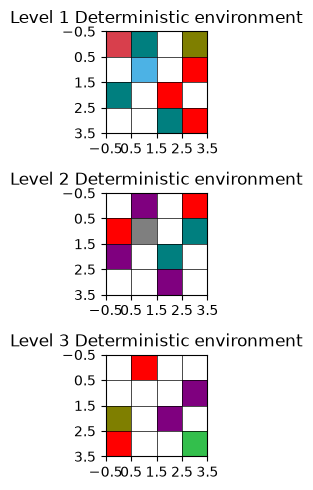

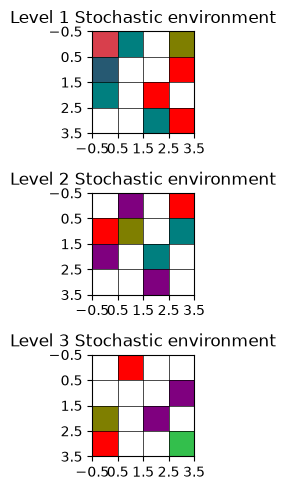

In [5]:
dEnv.render()
sEnv.render()

In [6]:
#recoded from scratch and verified with the working example.
import pandas as pd
def train_q_learning( #declaration header copied from the sample code
    env,
    episodes=500,
    alpha=0.3,
    gamma=0.9,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.99,
    seed=69420, #changed the seed
):
  q_table = np.zeros((env.observation_space.n,env.action_space.n))
  cumulatedRewards = []
  epsilons = []
  steps = []
  wasTerminated = []
  epsilon = epsilon_start
  rng = np.random.default_rng(seed)

  for episode in range(episodes):
    state, _ = env.reset(seed = seed+episode)
    episodeRewards = 0
    episodeSteps = 0
    while True:
      if rng.random() < epsilon: #if less than epsilon, we explore
        action = int(rng.integers(env.action_space.n))
      else: #if not less than epsilon, we exploit
        bestActions = np.flatnonzero(q_table[state] == q_table[state].max())  #from sample code
        action = int(rng.choice(bestActions))
      nextState, reward, terminated, truncated, _ = env.step(action)
      futureValue = 0.0 if terminated else np.max(q_table[nextState])
      q_table[state, action] += alpha*(reward+gamma*futureValue-q_table[state, action])
      episodeRewards += reward
      episodeSteps += 1
      state = nextState
      if terminated or truncated:
        break
    cumulatedRewards.append(round(episodeRewards,2))
    epsilons.append(epsilon)
    steps.append(episodeSteps)
    wasTerminated.append(terminated)
    epsilon = max(epsilon * epsilon_decay, epsilon_min)
  terminDF = pd.DataFrame(zip(steps, wasTerminated), columns = ['steps', 'wasTerminated'])  #Change: Converts the list of episode data into a dataframe for processing
  return q_table, cumulatedRewards, epsilons, terminDF

dEnv=DeterministicCustomEnvironment()
sEnv=StochasticCustomEnvironment()
d_q_table, d_cumulatedRewards, d_epsilons, d_terminDF = train_q_learning(dEnv)
s_q_table, s_cumulatedRewards, s_epsilons, s_terminDF = train_q_learning(sEnv)

In [7]:
print("Number of Deterministic Episodes that Terminated:",d_terminDF[d_terminDF['wasTerminated']==True].shape[0])
print("Number of Deterministic Episodes that were Truncated:",d_terminDF[d_terminDF['wasTerminated']==False].shape[0])
pd.set_option('display.max_rows', None)
print("Deterministic Episode step count frequencies:",d_terminDF['steps'].value_counts())
print(d_cumulatedRewards[450:])
print("Total Episodes:", 500)

Number of Deterministic Episodes that Terminated: 393
Number of Deterministic Episodes that were Truncated: 107
Deterministic Episode step count frequencies: steps
100    107
25      92
27      58
26      53
28      38
29      34
31      23
30      17
32      13
33      11
35       9
34       6
36       6
51       3
41       3
38       3
45       3
46       2
39       2
37       2
68       1
75       1
74       1
86       1
67       1
72       1
50       1
69       1
70       1
55       1
44       1
48       1
64       1
40       1
43       1
Name: count, dtype: int64
[51.5, 51.4, 50.3, 51.4, 51.4, 51.5, 51.3, 51.4, 50.8, 50.9, 51.4, 51.5, 51.5, 51.2, 51.5, 51.5, 51.3, 51.5, 51.4, 51.5, 51.3, 51.5, 51.2, 51.5, 51.0, 51.5, 51.3, 51.0, 51.5, 50.7, 50.5, 51.2, 51.5, 51.5, 51.2, 51.5, 50.8, 51.5, 51.3, 50.2, 51.3, 51.5, 51.1, 51.1, 51.4, 51.1, 51.4, 51.3, 51.5, 51.4]
Total Episodes: 500


In [8]:
print("Number of Stochastic Episodes that Terminated:",s_terminDF[s_terminDF['wasTerminated']==True].shape[0])
print("Number of Stochastic Episodes that were Truncated:",s_terminDF[s_terminDF['wasTerminated']==False].shape[0])
pd.set_option('display.max_rows', None)
print("Stochastic Episode step count frequencies:",s_terminDF['steps'].value_counts())
print(s_cumulatedRewards[450:])
print("Total Episodes:", 500)

Number of Stochastic Episodes that Terminated: 323
Number of Stochastic Episodes that were Truncated: 177
Stochastic Episode step count frequencies: steps
100    177
35      18
45      18
43      17
44      15
37      14
46      14
42      14
51      13
32      13
38      13
39      12
36      11
40      11
49       9
47       9
41       9
52       8
34       8
48       7
31       7
33       7
57       6
50       6
53       5
55       5
56       5
54       5
30       5
62       3
60       3
61       3
29       3
71       2
67       2
89       2
58       2
79       1
82       1
99       1
66       1
90       1
86       1
74       1
76       1
87       1
68       1
91       1
70       1
75       1
59       1
63       1
28       1
69       1
64       1
25       1
Name: count, dtype: int64
[44.7, 50.4, 49.7, 48.1, 50.3, 44.5, 50.0, 46.9, 47.0, 45.6, 49.4, 47.2, 46.2, 50.7, 50.5, 48.4, 50.1, 50.9, 46.1, 49.2, 50.1, 48.4, 47.7, 47.9, 49.4, 50.4, 48.8, 49.9, 48.4, 49.4, 49.3, 49.1, 49.1, 49.3

C:\Users\andy5\AppData\Local\Temp\ipykernel_6888\3951774191.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


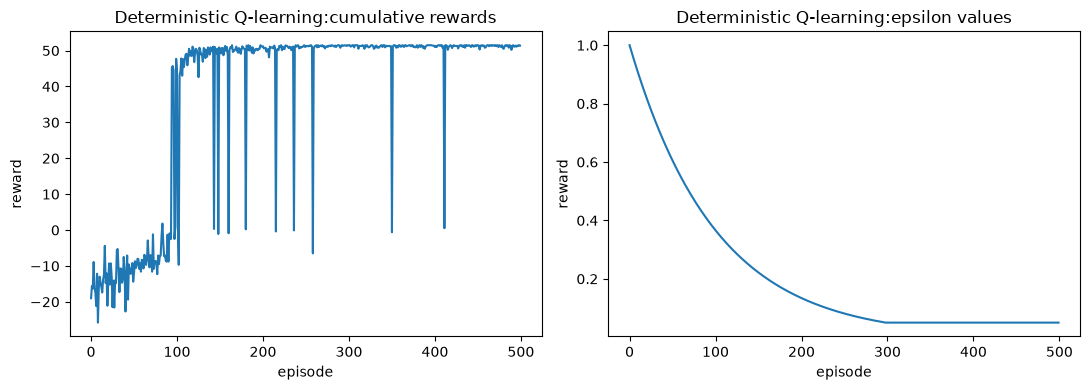

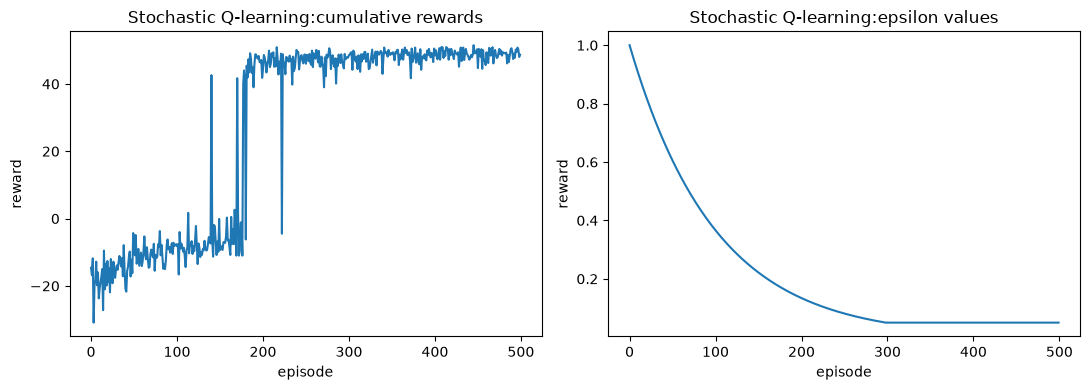

In [9]:
def makeNsavePlots(rewards, epsilons, title, filename):
  fig, axes = plt.subplots(1, 2, figsize=(11, 4)) #creates subplots, from example code
  axes[0].plot(rewards)
  axes[0].set(title = f'{title}:cumulative rewards', xlabel = 'episode', ylabel = 'reward')
  axes[1].plot(epsilons)
  axes[1].set(title = f'{title}:epsilon values', xlabel = 'episode', ylabel = 'reward')
  fig.tight_layout()
  fig.savefig(PLOT_DIR / filename, dpi = 160)
  fig.show()

makeNsavePlots(d_cumulatedRewards,d_epsilons, "Deterministic Q-learning", "q_learning_deterministic.png")
makeNsavePlots(s_cumulatedRewards,s_epsilons,"Stochastic Q-learning", "q_learning_stochastic.png")

Alternative Algorithm: SARSA

In [10]:
#recoded from scratch and verified with the working example.
import pandas as pd
def epsilonGreedy(Q,env,epsilon,rng,state): #re-encapsuled the epsilonGreedy functionality into its own function. However, the original Q-learning algorithm untouched
  if rng.random() < epsilon: #if less than epsilon, we explore
    return int(rng.integers(env.action_space.n))
  else: #if not less than epsilon, we exploit
    bestActions = np.flatnonzero(Q[state] == Q[state].max())  #from sample code
    return int(rng.choice(bestActions))

def train_SARSA( #built around the Q-learning version modified for SARSA, largely copied from the Q-learning above (which was based on the example code)
    env,
    episodes=500,
    alpha=0.3,
    gamma=0.9,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.99,
    seed=69420, #changed the seed
):
  q_table = np.zeros((env.observation_space.n,env.action_space.n))
  cumulatedRewards = []
  epsilons = []
  steps = []
  wasTerminated = []
  epsilon = epsilon_start
  rng = np.random.default_rng(seed)

  for episode in range(episodes):
    state, _ = env.reset(seed = seed+episode)
    action = epsilonGreedy(q_table,env,epsilon,rng,state)
    episodeRewards = 0
    episodeSteps = 0
    while True:
      nextState, reward, terminated, truncated, _ = env.step(action)
      nextAction = epsilonGreedy(q_table,env,epsilon,rng,nextState)
      rewardUpdate = reward if (terminated or truncated) else reward+gamma*q_table[nextState, nextAction] #updates based off determined next action, not off the hypothetical best action
      q_table[state, action] += alpha*(rewardUpdate-q_table[state, action])
      episodeRewards += reward
      episodeSteps += 1
      if terminated or truncated:
        break
      state = nextState
      action = nextAction
    cumulatedRewards.append(round(episodeRewards,2))
    epsilons.append(epsilon)
    steps.append(episodeSteps)
    wasTerminated.append(terminated)
    epsilon = max(epsilon * epsilon_decay, epsilon_min)
  terminDF = pd.DataFrame(zip(steps, wasTerminated), columns = ['steps', 'wasTerminated'])  #Change: Converts the list of episode data into a dataframe for processing
  return q_table, cumulatedRewards, epsilons, terminDF

sarsaEnv=DeterministicCustomEnvironment()
sarsa_table, sarsa_cumulatedRewards, sarsa_epsilons, sarsa_terminDF = train_SARSA(sarsaEnv)

In [11]:
print("Number of SARSA Episodes that Terminated:",sarsa_terminDF[sarsa_terminDF['wasTerminated']==True].shape[0])
print("Number of SARSA Episodes that were Truncated:",sarsa_terminDF[sarsa_terminDF['wasTerminated']==False].shape[0])
pd.set_option('display.max_rows', None)
print("SARSA Episode step count frequencies:",sarsa_terminDF['steps'].value_counts())
print(sarsa_cumulatedRewards[450:])
print("Total Episodes:", 500)

Number of SARSA Episodes that Terminated: 373
Number of SARSA Episodes that were Truncated: 127
SARSA Episode step count frequencies: steps
100    127
25      82
27      58
26      57
28      43
29      26
31      23
30      20
32      10
33       9
34       7
55       3
53       2
71       2
35       2
85       2
39       2
60       2
45       2
37       2
22       2
69       1
89       1
70       1
49       1
93       1
57       1
67       1
38       1
42       1
54       1
87       1
79       1
86       1
51       1
43       1
23       1
36       1
Name: count, dtype: int64
[50.9, 51.2, 51.5, 51.4, 50.9, 51.5, 51.5, 51.1, 51.3, 51.0, 51.5, 51.0, 51.3, 51.5, 51.3, 51.5, 50.3, 51.3, 51.3, 51.5, 51.4, 50.9, 51.2, 51.5, 51.1, 50.8, 51.5, 51.4, 51.3, 51.5, 51.3, 51.5, 51.3, 51.4, 51.3, 51.4, 51.5, 51.3, 51.4, 50.7, 50.5, 51.1, 49.0, 50.8, 51.0, 51.3, 51.5, 51.5, 50.2, 50.9]
Total Episodes: 500


C:\Users\andy5\AppData\Local\Temp\ipykernel_6888\3951774191.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


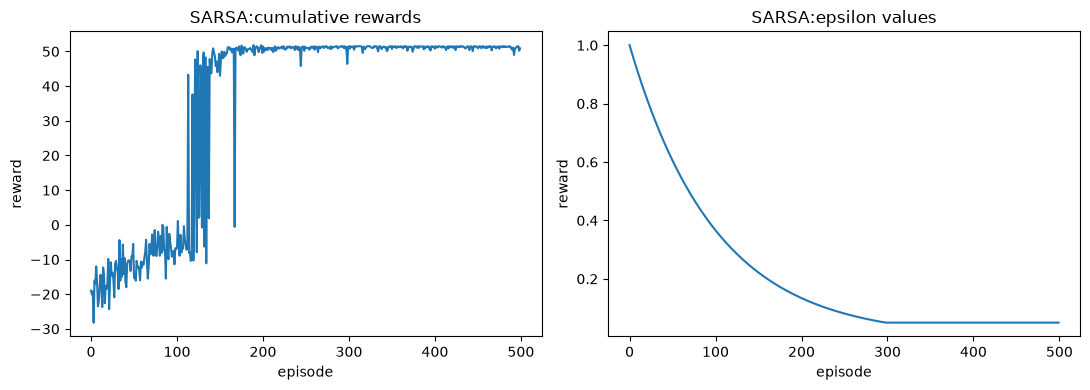

In [12]:
makeNsavePlots(sarsa_cumulatedRewards,sarsa_epsilons, "SARSA", "sarsa.png")

Hyperparameter Experiments:
*   Factor 1: epsilon_decay\
    Trial values:{.9,.99,.999}
*   Factor 2: gamma\
    Trial values: {.7,.9,.99}
*   Factor 3: maxTimesteps\
    Trial values: {100,150,200}




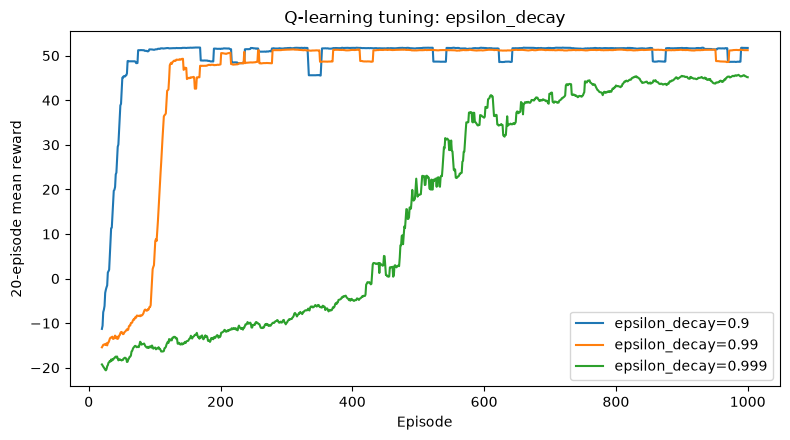

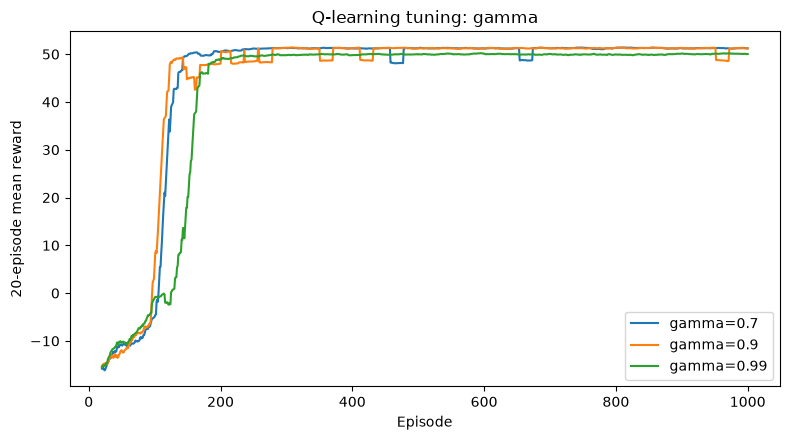

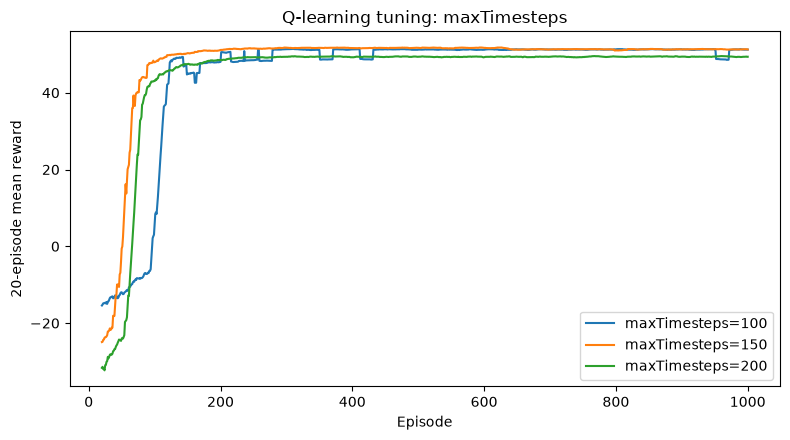

In [13]:
#mostly copied/recreated from the example code (its just a program handling input, output, and display of train_q_learning)
expVals = {"epsilon_decay":[.9,.99,.999], "gamma":[.7,.9,.99], "maxTimesteps":[100,150,200]} #changed hyperparameters and the testing values
baselineVals = {"epsilon_decay":.99, "gamma":.9}
tuning_results = {}
for para,vals in expVals.items():
  fig, ax = plt.subplots(figsize=(8,4.5))
  for val in vals:
    if para == "maxTimesteps":  #biggest difference is the different handling of "maxTimesteps". It goes into DeterministicCustomEnvironment not train_q_learning
      _, rewardOut,_,_ = train_q_learning(DeterministicCustomEnvironment(maxTimesteps=val), episodes = 1000)
    else:
      basecopy = dict(baselineVals)
      basecopy[para] = val
      _, rewardOut,_,_ = train_q_learning(DeterministicCustomEnvironment(), episodes = 1000, **basecopy)
    tuning_results[(para, val)] = rewardOut  #back to code sourced from the example code
    moving_average = np.convolve(rewardOut, np.ones(20) / 20, mode="valid")
    ax.plot(np.arange(20, len(rewardOut) + 1), moving_average, label=f"{para}={val}")
  ax.set(title=f"Q-learning tuning: {para}", xlabel="Episode", ylabel="20-episode mean reward")
  ax.legend()
  fig.tight_layout()
  fig.savefig(PLOT_DIR / f"tuning_{para}.png", dpi=160)
  plt.show()


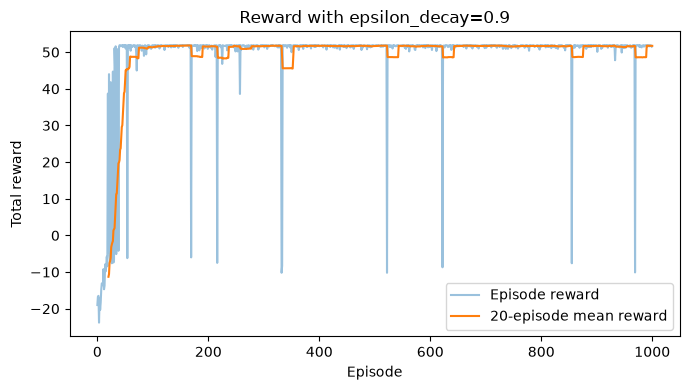

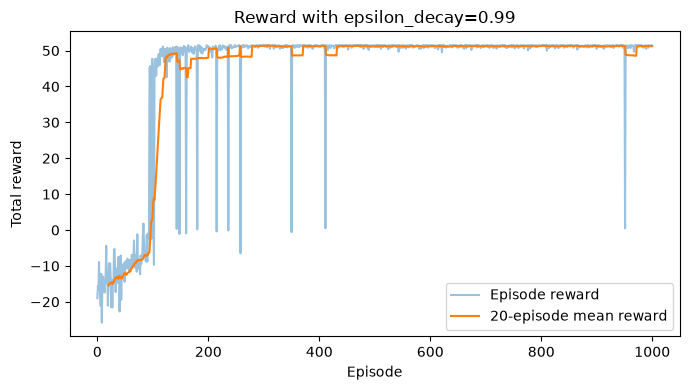

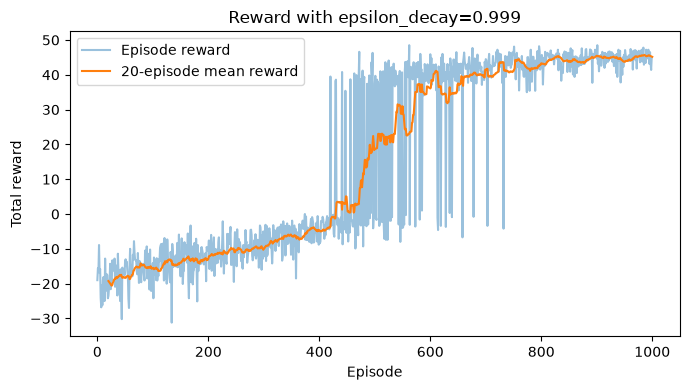

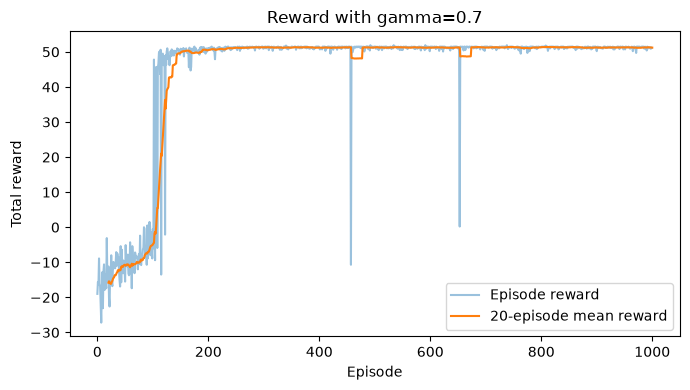

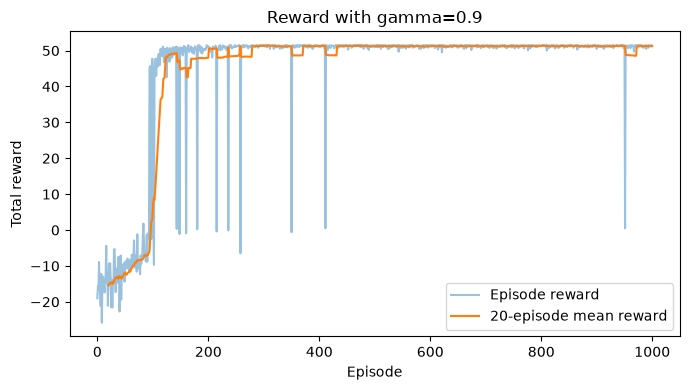

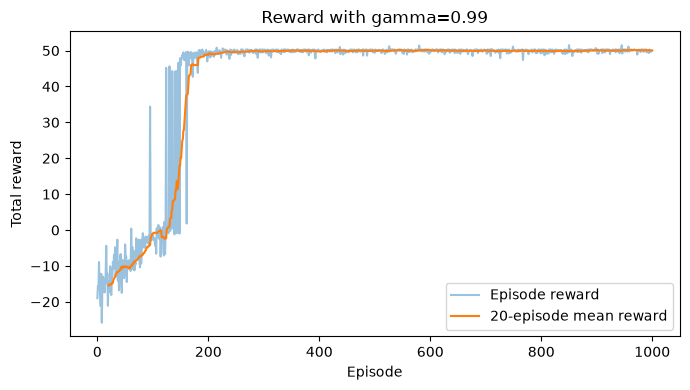

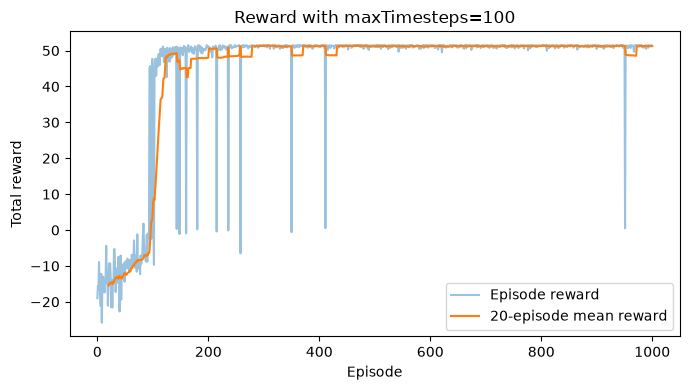

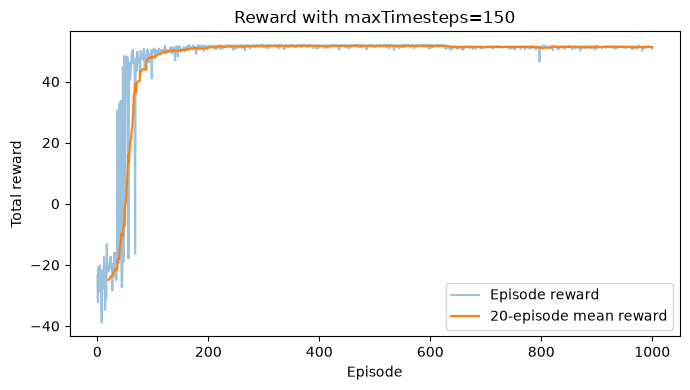

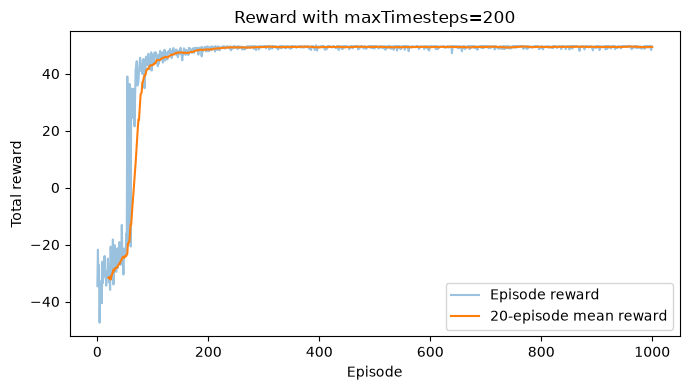

In [14]:
for (para,val),rewardOut in tuning_results.items():
  moving_average = np.convolve(rewardOut, np.ones(20) / 20, mode="valid")
  plt.figure(figsize=(7, 4))
  plt.plot(rewardOut, alpha=0.45, label="Episode reward")
  plt.plot(np.arange(20, len(rewardOut) + 1), moving_average, label="20-episode mean reward")
  plt.title(f"Reward with {para}={val}")
  plt.xlabel("Episode")
  plt.ylabel("Total reward")
  plt.legend()
  plt.tight_layout()
  plt.savefig(PLOT_DIR / f"tuning_detail_{para}_{val}.png", dpi=160)
  plt.show()


